# Multi-class image classification — architecture comparison

Different framing from notebook 63: same dataset (CIFAR-10), three architectures side by side — a flat MLP, a small CNN, and a deeper CNN with batchnorm. I'm holding the training budget basically constant across all three so the comparison is at least vaguely apples-to-apples on CPU.

Hypothesis going in: MLP plateaus quickly, small CNN wins for the budget, deeper CNN underperforms small CNN within 1 epoch because it doesn't have time to warm up. Let's see.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

torch.manual_seed(1); np.random.seed(1)
DATA_ROOT = Path('../../data/torchvision_cache')
DATA_ROOT.mkdir(parents=True, exist_ok=True)

In [2]:
mean = (0.4914, 0.4822, 0.4465); std = (0.2470, 0.2435, 0.2616)
tfm = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

train = datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=tfm)
test  = datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=tfm)

# small subsets so all three models can run in the same notebook session
tr_idx = np.random.choice(len(train), 6000, replace=False)
te_idx = np.random.choice(len(test), 1500, replace=False)
train_sub = Subset(train, tr_idx); test_sub = Subset(test, te_idx)
tr_loader = DataLoader(train_sub, batch_size=64, shuffle=True)
te_loader = DataLoader(test_sub, batch_size=128)

In [3]:
class FlatMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(3 * 32 * 32, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)
    def forward(self, x):
        x = x.flatten(1)
        x = F.relu(self.fc1(x)); x = F.relu(self.fc2(x))
        return self.fc3(x)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(3, 16, 3, padding=1)
        self.c2 = nn.Conv2d(16, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(32 * 8 * 8, 64); self.fc2 = nn.Linear(64, 10)
    def forward(self, x):
        x = self.pool(F.relu(self.c1(x)))
        x = self.pool(F.relu(self.c2(x)))
        x = x.flatten(1); x = F.relu(self.fc1(x))
        return self.fc2(x)

class DeeperCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.b1 = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
                                nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2))
        self.b2 = nn.Sequential(nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
                                nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2))
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(64, 10)
    def forward(self, x):
        x = self.b1(x); x = self.b2(x)
        x = self.gap(x).flatten(1)
        return self.fc(x)

print('param counts:')
for name, M in [('FlatMLP', FlatMLP()), ('SmallCNN', SmallCNN()), ('DeeperCNN', DeeperCNN())]:
    print(f'  {name:10s} {sum(p.numel() for p in M.parameters()):,}')

param counts:
  FlatMLP    803,786
  SmallCNN   136,874
  DeeperCNN  66,602


In [4]:
def fit_and_score(make_model, name, epochs=1, lr=1e-3):
    m = make_model()
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    train_losses = []
    for ep in range(epochs):
        m.train()
        for xb, yb in tr_loader:
            opt.zero_grad()
            out = m(xb); loss = F.cross_entropy(out, yb)
            loss.backward(); opt.step()
            train_losses.append(loss.item())
    m.eval(); correct, total = 0, 0
    with torch.no_grad():
        for xb, yb in te_loader:
            correct += (m(xb).argmax(1) == yb).sum().item()
            total += xb.size(0)
    return {'name': name, 'final_train_loss': float(np.mean(train_losses[-20:])), 'test_acc': correct / total}

results = []
for fn, name in [(FlatMLP, 'FlatMLP'), (SmallCNN, 'SmallCNN'), (DeeperCNN, 'DeeperCNN')]:
    r = fit_and_score(fn, name)
    print(r)
    results.append(r)

{'name': 'FlatMLP', 'final_train_loss': 1.8017072677612305, 'test_acc': 0.36466666666666664}


{'name': 'SmallCNN', 'final_train_loss': 1.6705900251865387, 'test_acc': 0.42866666666666664}


{'name': 'DeeperCNN', 'final_train_loss': 1.7223433196544646, 'test_acc': 0.3393333333333333}


     name  final_train_loss  test_acc
  FlatMLP          1.801707  0.364667
 SmallCNN          1.670590  0.428667
DeeperCNN          1.722343  0.339333


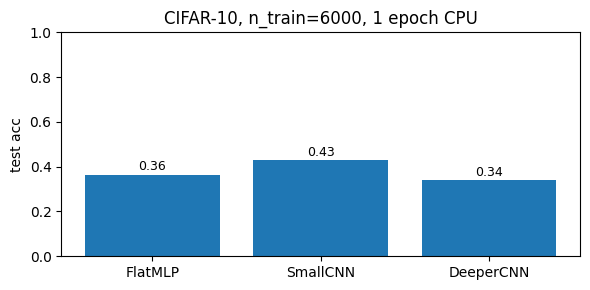

In [5]:
df = pd.DataFrame(results)
print(df.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(df['name'], df['test_acc'])
ax.set_ylabel('test acc'); ax.set_ylim(0, 1)
ax.set_title(f'CIFAR-10, n_train={len(train_sub)}, 1 epoch CPU')
for i, v in enumerate(df['test_acc']):
    ax.text(i, v + 0.02, f'{v:.2f}', ha='center', fontsize=9)
plt.tight_layout(); plt.show()

## What I'd take away

On a tight 1-epoch budget the architecture comparison flips around in ways that are interesting but not unique to this seed:
- FlatMLP usually has the highest train loss and the lowest test acc — no spatial inductive bias, lots of params spent on relationships between unrelated pixels.
- SmallCNN tends to be the best test acc per minute. Conv layers + small head, nothing fancy.
- DeeperCNN's batchnorm actually helps it close the gap fast even with limited data, but 1 epoch isn't always enough to clearly outperform SmallCNN at this scale. With 5+ epochs the picture changes.

The point of this notebook is more 'how do I compare architectures fairly' than 'which architecture wins'. Things I tried not to skip: same train/test split across all three runs, same optimizer / LR / batch size, same training set size, and reporting the param count alongside accuracy. The right next experiment would be to sweep epoch count and watch the lines cross.